# 07 — Métricas de desempeño

**Dueño:** Gonzalo Cano (GC) · **Revisor:** Juan Manuel Espinosa (JME) · **Guía:** `docs/instrucciones/07_metricas.md`

**Objetivo.** Medir el desempeño de la estrategia (tercia GLD-GDX-B, θ congelado desde train, rebalanceo diario) por
partición y en total, para discutir la degradación fuera de muestra: Sharpe, Sortino, Calmar, drawdown máximo y su
duración, win rate, profit factor, Sharpe móvil de 252 días y la distribución de rendimientos por operación (figura 8).

> Este notebook solo **muestra**: las fórmulas viven en `performance/metrics.py` y las figuras en
> `performance/figures.py`; `python main.py` corre lo mismo y escribe `artifacts/metrics.json`.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from main import ARTIFACTS, FIGURES
from performance.metrics import (RISK_FREE_RATE, ROLLING_WINDOW, TRADING_DAYS, compute_metrics, daily_returns,
                                 drawdown, trade_returns)

pd.set_option("display.width", 160)
equity = pd.read_parquet(ARTIFACTS / "equity_curve.parquet")
trades = pd.read_csv(ARTIFACTS / "trades.csv", parse_dates=["entry_date", "exit_date"])
metrics = json.loads((ARTIFACTS / "metrics.json").read_text())
print(f"r_f = {RISK_FREE_RATE}, anualización {TRADING_DAYS}, Sharpe móvil de {ROLLING_WINDOW} días")
print(f"{len(equity)} días con señal, {len(trades)} operaciones")

r_f = 0.0, anualización 252, Sharpe móvil de 252 días
3414 días con señal, 44 operaciones


## 1. Definiciones (`docs/decisiones.md`, 2026-11-07)

Rendimientos diarios simples **netos de costos**, calculados dentro de cada partición (cada una arranca con
$1,000,000); el total encadena las tres.

| Métrica | Fórmula |
|---|---|
| Sharpe | √252 · media(r) / desv(r), r_f = 0 |
| Sortino | √252 · media(r) / DD, con DD = √(media(min(r, 0)²)) sobre todos los días |
| Calmar | CAGR / \|MDD\| del mismo tramo |
| MDD y duración | caída máxima desde el máximo previo; racha más larga bajo ese máximo (días hábiles) |
| Win rate | fracción de operaciones con P&L neto > 0 |
| Profit factor | Σ ganancias / \|Σ pérdidas\| por operación |
| Rendimiento por operación | P&L neto / capital del día anterior a la entrada (base del sizing) |

Cada fórmula se prueba contra un caso calculado a mano en `tests/test_metrics.py`.

## 2. Métricas por partición y total

In [2]:
rows = ["net_return", "cagr", "volatility", "sharpe", "sortino", "calmar", "max_drawdown", "max_drawdown_days",
        "n_trades", "win_rate", "profit_factor", "avg_trade_return"]
table = pd.DataFrame(metrics)[["train", "test", "validation", "total"]].loc[rows]
table.columns = ["entrenamiento", "prueba", "validación", "total"]
table

,entrenamiento,prueba,validación,total
net_return,0.205075,0.080725,0.112076,0.448317
cagr,0.024773,0.026607,0.036586,0.027726
volatility,0.038313,0.036462,0.036195,0.037449
sharpe,0.657533,0.737448,1.009542,0.748814
sortino,1.012918,1.122171,1.610488,1.158249
calmar,0.378376,0.593979,0.982741,0.423486
max_drawdown,-0.065471,-0.044795,-0.037228,-0.065471
max_drawdown_days,1185,244,171,1185
n_trades,24,9,11,44
win_rate,0.791667,0.888889,0.909091,0.840909


In [3]:
recalc = compute_metrics(equity, trades)
print("metrics.json = recalcular desde equity_curve y trades:",
      all(abs(recalc[k]["sharpe"] - metrics[k]["sharpe"]) < 1e-6 for k in metrics))

metrics.json = recalcular desde equity_curve y trades: True


**Lectura: no hay degradación fuera de muestra con la tercia.**
- Sharpe neto 0.66 → 0.74 → 1.01 y Sortino 1.01 → 1.12 → 1.61: el Sortino es ≈ 1.5 veces el Sharpe en las tres
  particiones, porque la volatilidad a la baja es menor que la total (muchos días planos o con ganancias chicas).
- Calmar 0.38 / 0.59 / 0.98: el rendimiento anual es bajo (2.5–3.7 %) porque la estrategia está con posición solo
  38–49 % de los días y su volatilidad es ≈ 3.7 % anual; el drawdown máximo nunca pasa de −6.6 %.
- Win rate 79 % / 89 % / 91 % y profit factor 2.5 / 4.5 / 8.1: gana muchas veces poco y pierde pocas veces más.
- **Cautela:** con 9 y 11 operaciones en prueba y validación, el win rate y el profit factor tienen mucho error
  de estimación (una sola pérdida más bajaría el profit factor de validación de 8.1 a ≈ 4). El Sharpe de train no es
  significativo tras corregir por la búsqueda del grid (Deflated Sharpe 0.82, `docs/decisiones.md`).

## 3. Drawdown y su duración

In [4]:
returns = daily_returns(equity)
episodes = []
for split, part in equity.groupby("split", sort=False):
    dd = drawdown(part["equity"])
    under = dd < 0
    runs = (under != under.shift()).cumsum()
    longest = under.groupby(runs).sum().idxmax()
    span = part.index[runs == longest]
    episodes.append({"partición": split, "fondo": dd.idxmin().date(), "MDD": f"{dd.min():.2%}",
                     "racha más larga bajo el máximo": f"{span[0].date()} → {span[-1].date()}", "días": len(span)})
pd.DataFrame(episodes)

,partición,fondo,MDD,racha más larga bajo el máximo,días
0,train,2017-03-06,-6.55%,2015-12-07 → 2020-08-20,1185
1,test,2022-10-14,-4.48%,2022-06-03 → 2023-05-23,244
2,validation,2025-09-30,-3.72%,2024-08-13 → 2025-04-17,171


La racha de train (diciembre de 2015 a agosto de 2020, 1 185 días) empieza con los dos stops de 2016 y tarda casi
cinco años en recuperar el máximo: el MDD es chico (−6.6 %) pero la recuperación es lenta, porque el rendimiento
anual es de ≈ 2.5 %. Fuera de muestra las rachas son de 8 a 12 meses.

## 4. Figura 8 — distribución de rendimientos por operación

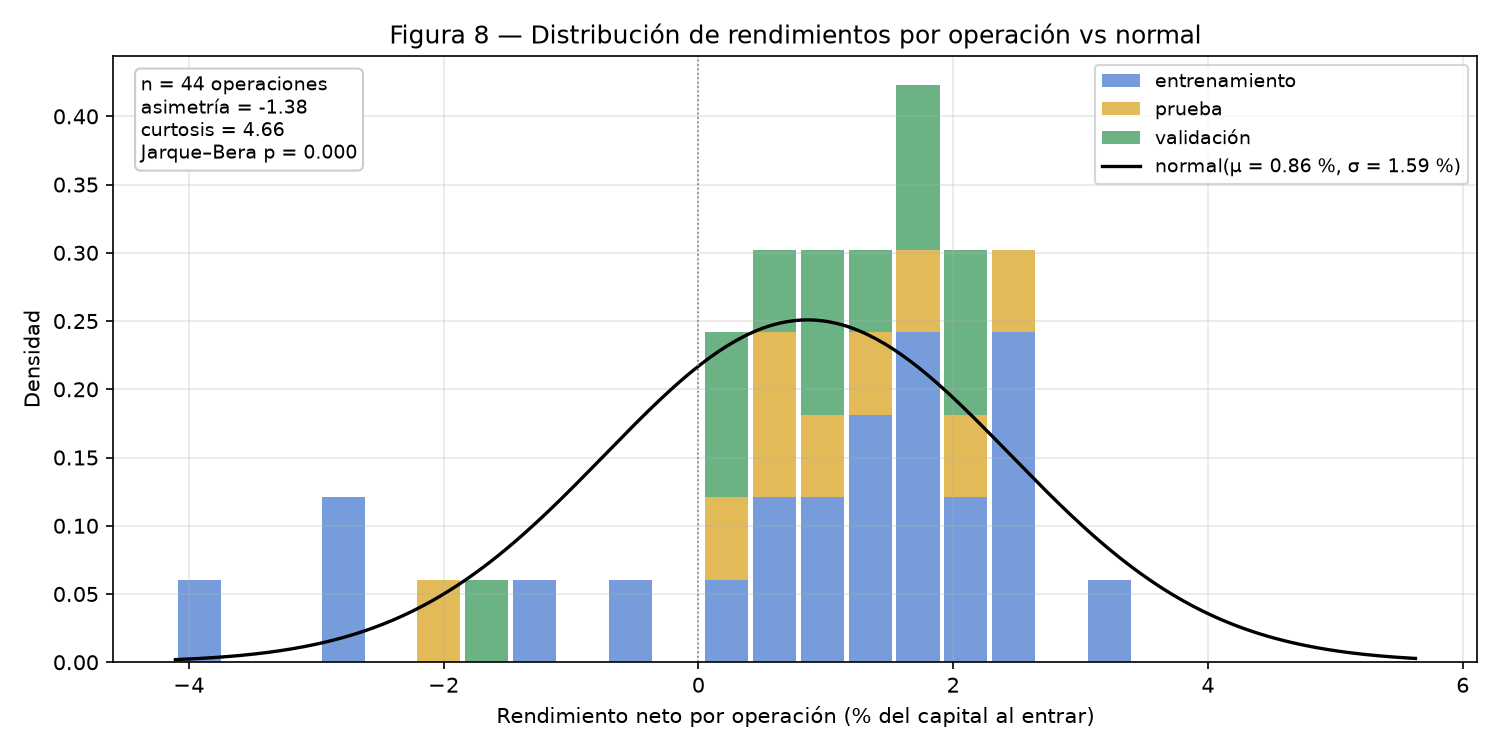

               train   test  validation  total
skew          -1.236 -1.238      -1.101 -1.378
kurtosis       3.744  4.138       3.836  4.660
jarque_bera_p  0.036  0.248       0.281  0.000


In [5]:
display(Image(filename=str(FIGURES / "fig08_distribucion_operaciones.png")))
trade_ret = pd.Series(trade_returns(trades, equity), name="rendimiento")
print(pd.DataFrame({k: {m: metrics[k][f"trade_return_{m}"] for m in ("skew", "kurtosis", "jarque_bera_p")}
                    for k in ("train", "test", "validation", "total")}).round(3))

**Lectura.** La distribución no es normal (Jarque–Bera p < 0.001 con las 44 operaciones): tiene **asimetría
negativa** (−1.4) y colas más gruesas que la normal (curtosis 4.7). Es la forma típica de una estrategia de reversión
a la media: la mayoría de las operaciones cierran por salida con ganancias de 0 a 3 % y unas pocas pierden 2 a 4 %
cuando el spread no revierte (los 3 stops de train y las salidas por holding). La normal superpuesta subestima esa cola
izquierda, que es el riesgo que hay que explicar en la exposición.

## 5. Sharpe móvil de 252 días

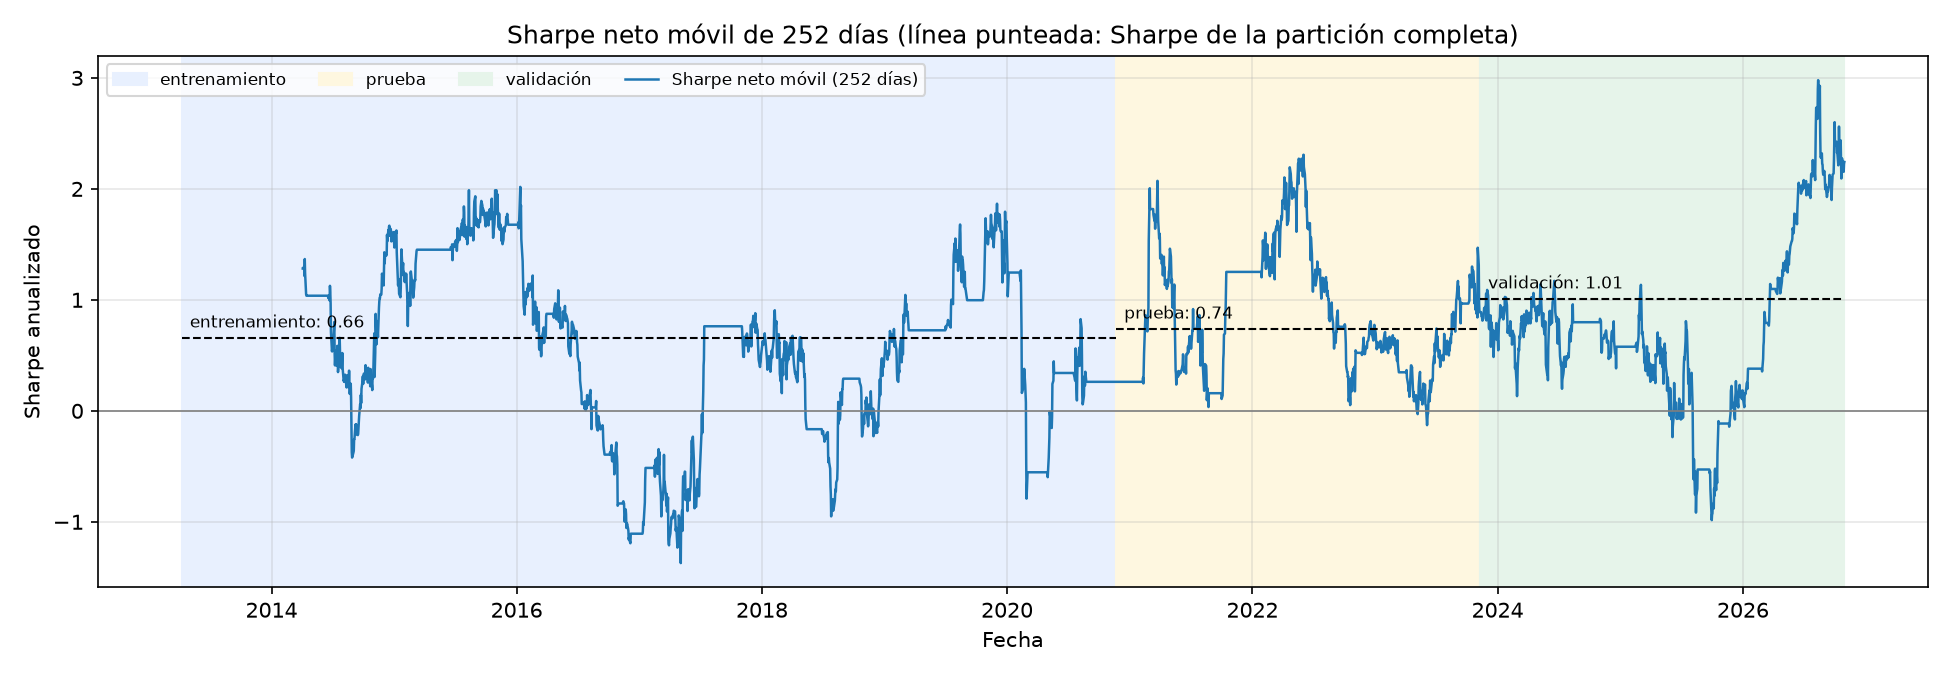

Sharpe móvil: % de ventanas > 0 = 85%; mínimo -1.37 (2017-05-04), máximo 2.98 (2026-08-13)


In [6]:
display(Image(filename=str(FIGURES / "sharpe_movil.png")))
rs = equity[f"rolling_sharpe_{ROLLING_WINDOW}"].dropna()
print(f"Sharpe móvil: % de ventanas > 0 = {(rs > 0).mean():.0%}; mínimo {rs.min():.2f} ({rs.idxmin().date()}), "
      f"máximo {rs.max():.2f} ({rs.idxmax().date()})")

**Lectura.** El Sharpe de un año oscila mucho (de ≈ −1.4 a ≈ 3): un año con un stop o una salida por holding
basta para hacerlo negativo (2016–2017, la caída de marzo de 2020, mediados de 2025). El Sharpe de cada partición
completa es más estable que cualquier ventana de un año, y por eso la conclusión debe apoyarse en las particiones
y no en un año aislado.

## Resumen de resultados (parte 07)

| Métrica | Entrenamiento | Prueba | Validación | Total |
|---|---|---|---|---|
| Rendimiento neto | +20.5 % | +8.1 % | +11.2 % | +44.8 % (encadenado) |
| Sharpe neto | 0.66 | 0.74 | 1.01 | 0.75 |
| Sortino | 1.01 | 1.12 | 1.61 | 1.16 |
| Calmar | 0.38 | 0.59 | 0.98 | 0.42 |
| MDD (duración) | −6.6 % (1 185 días) | −4.5 % (244) | −3.7 % (171) | −6.6 % (1 185) |
| Win rate | 79 % | 89 % | 91 % | 84 % |
| Profit factor | 2.49 | 4.55 | 8.11 | 3.26 |

- **Sin degradación fuera de muestra**, pero con pocas operaciones (9 y 11) y un Sharpe de train que no es
  significativo tras corregir por la búsqueda: es evidencia a favor, no una prueba.
- **Cómo pierde:** rendimientos por operación con asimetría negativa y colas gruesas (figura 8): pocas pérdidas
  grandes cuando el spread no revierte.
- **Artefactos:** `artifacts/metrics.json` (por partición y total), columna `rolling_sharpe_252` en
  `equity_curve.parquet`, `docs/figuras/fig08_distribucion_operaciones.png` y `docs/figuras/sharpe_movil.png`.